# pymc-generator quickstart

Generate a synthetic marketing-mix world with a **known causal truth**:

1. Configure a prior over worlds (`make_scm_prior`).
2. Draw one world (`sample_scm`) and inspect its DAG and mechanisms.
3. Look at the observed series (channels, covariates, outcome).
4. Look at the exact decomposition of the outcome into true components.
5. Draw a small corpus of many worlds (`sample_prior_predictive`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc_generator as pg

SEED = 42
print("pymc-generator", pg.__version__)

pymc-generator 0.0.2


## 1. Configure the prior

Maximum sizes per world: 3 media channels (treatments), 1 observed covariate, 1 latent confounder, 52 weekly steps. `n_cells` × `draws_per_cell` sets the corpus size used in step 5.

In [2]:
cfg = pg.make_scm_prior(
    n_treatments=3,
    n_covariates=1,
    n_latent=1,
    n_time_steps=52,
    n_cells=2,
    draws_per_cell=2,
    seed=SEED,
)

## 2. Draw one world

`describe_scm` prints the sampled DAG (C = channels, Z = covariates, D = latent, Y = outcome), edge coefficients, and per-channel carryover/saturation mechanisms.

In [3]:
world = pg.sample_scm(cfg, seed=SEED)
print(pg.describe_scm(world))

Dataset: scm (additive SCM)

Purpose:
  

Sizes: n_time_steps=52, n_treatments=3, n_covariates=1, n_latent=1, l_max=8, carryover_burn_in=8
Edge budget: None

Edge census: cy=2  dc=1  dy=1  zc=1

Active edges (with drawn coefficients):
  [cy] C1 -> Y   coef=+1.836
  [cy] C2 -> Y   coef=+0.659
  [dc] D1 -> C1   coef=+0.412
  [dy] D1 -> Y   coef=+0.251
  [zc] Z1 -> C2   coef=+0.208

Node connectivity (connected = directed path to Y; isolated = no
  edges at all, a deliberate zero-attribution null; dead-ends are
  never generated):
  C1=connected  C2=connected  C3=isolated  Z1=connected  D1=connected
  -> 1 isolated null node(s): attribution traps, the model must credit them zero.

Channels (mechanism + own-drive texture):
  C1: role=direct  beta=1.84  carryover=weibull(lam=6.6,k=2.5)  saturation=michaelis_menten(kappa_mult=1.17)  walk(mean=1.84,std=1.02,smooth=0.59)  hf_sigma=0.78  pulse(p=0.15,amp=4.84)
  C2: role=direct  beta=0.66  carryover=weibull(lam=7.0,k=1.9)  saturation=hill(slope

## 3. Observed data

What an MMM would see: channel spend, covariates and the outcome.

In [4]:
d = world.data
dates = pd.date_range("2025-01-06", periods=world.n_time_steps, freq="W-MON")

observed = pd.DataFrame(
    {
        **{f"C{k + 1}": d["treatments"][:, k] for k in range(world.n_treatments)},
        **{f"Z{j + 1}": d["covariates"][:, j] for j in range(world.n_covariates)},
        "Y": d["outcome"],
    },
    index=dates,
)
observed.head()

,C1,C2,C3,Z1,Y
2025-01-06,2.710533,1.609663,1.696433,-0.671178,5.418011
2025-01-13,8.749352,1.170090,2.012132,-0.750943,5.357714
2025-01-20,2.329993,1.528630,3.576755,-0.673178,5.385581
2025-01-27,3.266761,2.797987,2.127668,-0.643357,5.396379
2025-02-03,2.928371,0.437575,2.437711,-0.720211,5.457999


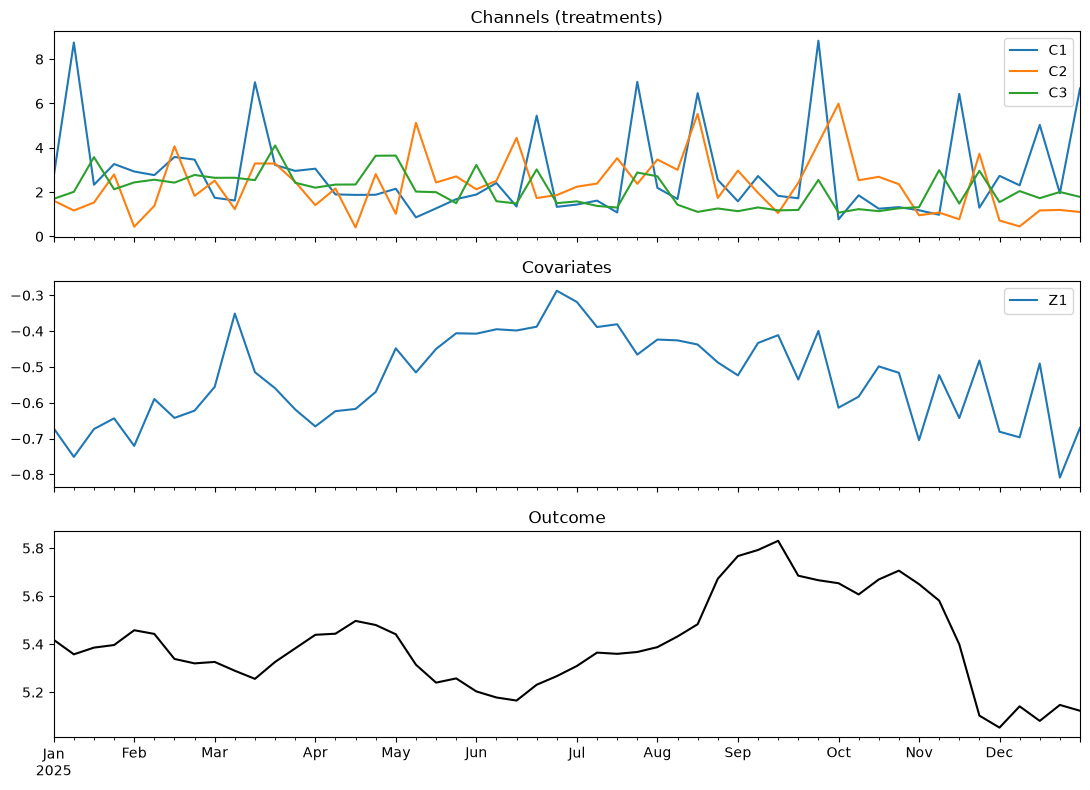

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
observed.filter(like="C").plot(ax=axes[0], title="Channels (treatments)")
observed.filter(like="Z").plot(ax=axes[1], title="Covariates")
observed["Y"].plot(ax=axes[2], title="Outcome", color="black")
fig.tight_layout()

## 4. True decomposition

The outcome is exactly the sum of its components, so the ground-truth contribution of each channel is known.

max |sum(components) - outcome|: 8.881784197001252e-16


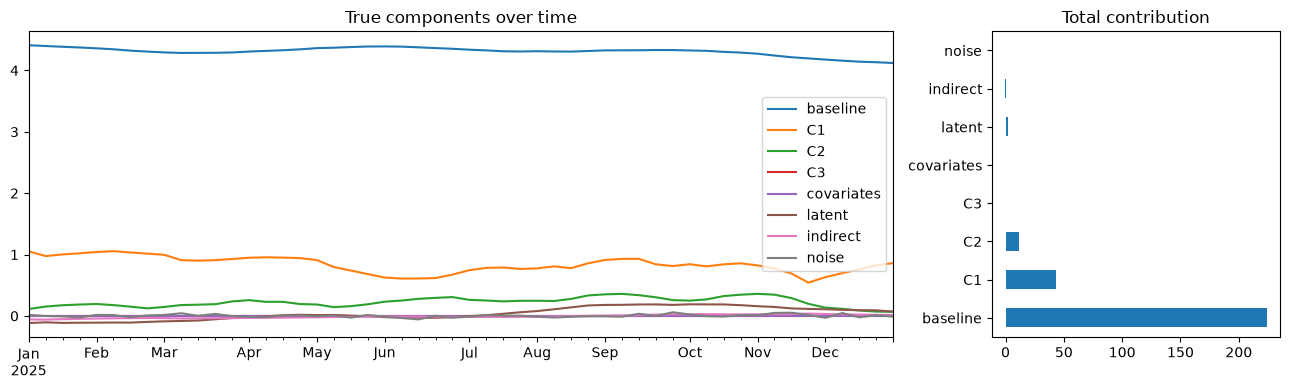

In [6]:
components = pd.DataFrame(
    {
        "baseline": d["baseline_intrinsic"],
        **{f"C{k + 1}": d["contributions"][:, k] for k in range(world.n_treatments)},
        "covariates": d["covariate_contribution"].sum(1),
        "latent": d["latent_unobserved_contribution"].sum(1),
        "indirect": d["indirect_effects_by_source"].sum(1),
        "noise": d["outcome_noise"],
    },
    index=dates,
)

assert np.allclose(components.sum(axis=1), observed["Y"])
print("max |sum(components) - outcome|:", world.identity_error())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
components.plot(ax=axes[0], title="True components over time")
components.sum().plot.barh(ax=axes[1], title="Total contribution")
fig.tight_layout()

## 5. A corpus of worlds

`sample_prior_predictive` draws `n_cells × draws_per_cell` worlds as stacked, padded arrays (`world, time, ...`), with active sizes sampled from the configured ranges.

treatment_raw                (4, 52, 3)
covariates                   (4, 52, 1)
outcome_raw                  (4, 52)
treatment_contribution_raw   (4, 52, 3)
active channels per world: [3 3 3 3]


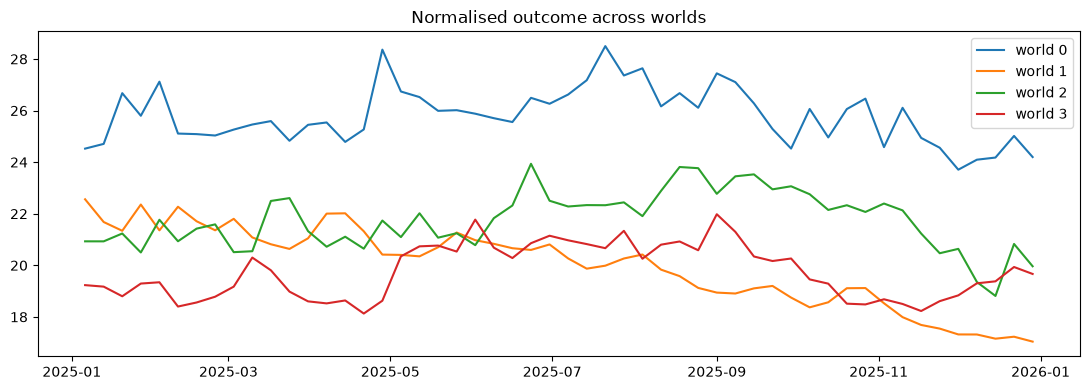

In [7]:
corpus = pg.sample_prior_predictive(cfg)

for key in ["treatment_raw", "covariates", "outcome_raw", "treatment_contribution_raw"]:
    print(f"{key:28} {corpus[key].shape}")
print("active channels per world:", corpus["n_treatments_active"])

fig, ax = plt.subplots(figsize=(11, 4))
for i, y in enumerate(corpus["outcome_norm"]):
    ax.plot(dates, y, label=f"world {i}")
ax.set_title("Normalised outcome across worlds")
ax.legend()
fig.tight_layout()